# Q2. Image Colorization using CNNs

### Intialization

##### Load centroids

In [1]:
import numpy as np

centroid_path="color_centroids.npy"

centroids=np.load(centroid_path).astype(np.float32)
if centroids.max()>1:
    centroids=centroids/255.0

print("CHECK")
print("=====")
print("Centroids shape: ",centroids.shape)
print("First 3 centroids: ",centroids[:3])
print("Range :",centroids.min(),centroids.max())


CHECK
=====
Centroids shape:  (24, 3)
First 3 centroids:  [[0.6260603  0.63038474 0.6212184 ]
 [0.15001483 0.1415019  0.12095974]
 [0.38839704 0.38176647 0.3473022 ]]
Range : 0.04982243 0.964958


#### Load CIFAR-10

In [2]:
import torch
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

cifar_train_data=datasets.CIFAR10(root="./data",train=True,download=True)
cifar_test_data=datasets.CIFAR10(root="./data",train=False,download=True)

print("CHECK")
print("=====")
print("Train Images :",len(cifar_train_data))
print("Test Images :",len(cifar_test_data))


100%|██████████| 170M/170M [00:03<00:00, 50.4MB/s]


CHECK
=====
Train Images : 50000
Test Images : 10000


##### Convert to grayscale

In [ ]:
def rgb_to_grayscale_tensor(img_rgb):
  """
  Convert a RGB image (H x W x 3) in numpy array format to a grayscale tensor (1 x H x W).
  Arguments:
    img_rgb: numpy array of shape (H x W x 3)
  Output:
    img_gray: torch tensor of shape (1 x H x W)
  """
  if img_rgb.dtype==np.uint8:
    img=img_rgb.astype(np.float32)/255.0
  else:
    img=img_rgb.astype(np.float32)

  img_gray=0.2989*img[...,0]+0.5870*img[...,1]+0.1140*img[...,2]
  return torch.from_numpy(img_gray).unsqueeze(0).float()

CHECK
=====


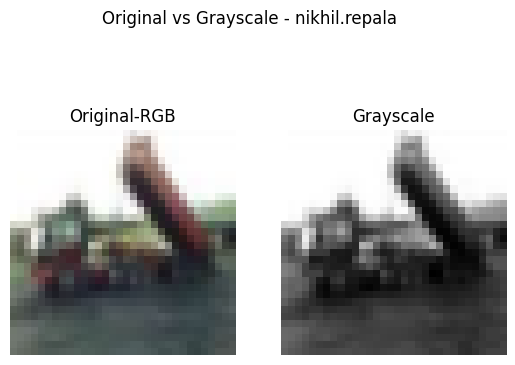

In [4]:

print("CHECK")
print("=====")
img_np=np.array(cifar_train_data[2][0])
gray_img=rgb_to_grayscale_tensor(img_np)

plt.subplot(1,2,1)
plt.imshow(img_np)
plt.title("Original-RGB")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(gray_img.squeeze(),cmap="gray")
plt.title("Grayscale")
plt.axis("off")

plt.suptitle("Original vs Grayscale - nikhil.repala")
plt.show()

##### Map Pixels to nearest Centroid

In [ ]:
def map_pixels_to_centroids(rgb_image,centroids):
  """
  Map each pixel in the RGB image to the index of the nearest centroid.
  Arguments:
    rgb_image: numpy array of shape (H x W x 3)
    centroids: numpy array of shape (K x 3)
  Output:
    idx_min: numpy array of shape (H x W) with the index of the nearest centroid for each pixel.
  """
  height,width,_=rgb_image.shape
  pixels=rgb_image.reshape(-1,1,3)

  centres=centroids.reshape(1,centroids.shape[0],3)
  distances=((pixels-centres)**2).sum(axis=2)
  idx_min=distances.argmin(axis=1)

  return idx_min.reshape(height,width).astype(np.int64)

CHECK
=====


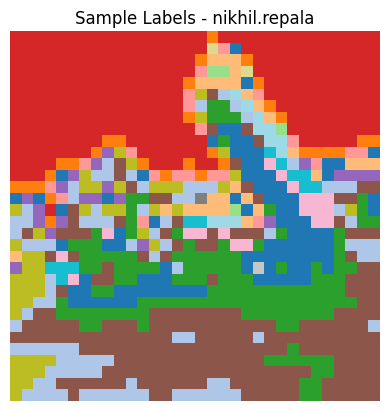

In [6]:
sample_rgb=np.array(cifar_train_data[2][0]).astype(np.float32)/255.0
sample_labels=map_pixels_to_centroids(sample_rgb,centroids)

print("CHECK")
print("=====")
plt.imshow(sample_labels,cmap="tab20")
plt.axis("off")
plt.title("Sample Labels - nikhil.repala")
plt.show()



### PyTorch Dataset Class

In [ ]:
from torch.utils.data import Dataset

class CIFAR10Dataset(Dataset):
  """
  CIFAR10Dataset class to handle CIFAR-10 dataset with grayscale images and pixel labels mapped to centroids.
  """
  def __init__(self,cifar_data,centroids):
    """
    initialize the dataset with CIFAR-10 data and centroids.
    Arguments:
      cifar_data: CIFAR-10 dataset object from torchvision.datasets
      centroids: numpy array of shape (K x 3) representing color centroids
    """
    self.cifar_data=cifar_data
    self.centroids=centroids

  def __len__(self):
    """
    return the length of the dataset
    """
    return len(self.cifar_data)

  def __getitem__(self,idx):
    """
    return the grayscale image and pixel labels mapped to centroids for a given index.
    Arguments:
      idx: index of the image in the dataset
    Output:
      img_gray: torch tensor of shape (1 x H x W) representing the grayscale image
      img_labels: torch tensor of shape (H x W) with the index of the nearest centroid for each pixel
      rgb_img: torch tensor of shape (3 x H x W) representing the original RGB image
    """
    img,_=self.cifar_data[idx]
    img_np=np.array(img).astype(np.float32)/255.0
    img_gray=rgb_to_grayscale_tensor(img_np)
    img_labels=map_pixels_to_centroids(img_np,self.centroids)
    rgb_img=torch.from_numpy(img_np.transpose(2,0,1)).float()
    return img_gray,torch.from_numpy(img_labels).long(),rgb_img

In [8]:
from torch.utils.data import DataLoader, random_split

train_full_dataset=CIFAR10Dataset(cifar_train_data,centroids)
test_dataset=CIFAR10Dataset(cifar_test_data,centroids)

n_total=len(train_full_dataset)
n_val=int(0.1*n_total)
n_train=n_total-n_val

train_dataset,val_dataset=random_split(train_full_dataset,[n_train,n_val],
                                       generator=torch.Generator().manual_seed(42))

train_loader=DataLoader(train_dataset,batch_size=64,shuffle=True,num_workers=2)
val_loader=DataLoader(val_dataset,batch_size=64,shuffle=False,num_workers=2)
test_loader=DataLoader(test_dataset,batch_size=64,shuffle=False,num_workers=2)

print("CHECK")
print("=====")
print("Train dataset size: ",len(train_dataset))
print("Validation dataset size: ",len(val_dataset))
print("Test dataset size: ",len(test_dataset))


CHECK
=====
Train dataset size:  45000
Validation dataset size:  5000
Test dataset size:  10000


##### Reconstruction

In [ ]:
def reconstruct_rgb_from_labels(labels,centroids):
  """
  Reconstruct RGB image from pixel labels and centroids.
  Arguments:
    labels: numpy array of shape (H x W) with the index of the nearest centroid for each pixel
    centroids: numpy array of shape (K x 3)
  Output:
    rgb: numpy array of shape (H x W x 3) representing the reconstructed RGB image
  """
  height,width=labels.shape
  rgb=centroids[labels.flatten()]
  rgb=rgb.reshape(height,width,3)
  return np.clip(rgb,0,1)

CHECK
=====


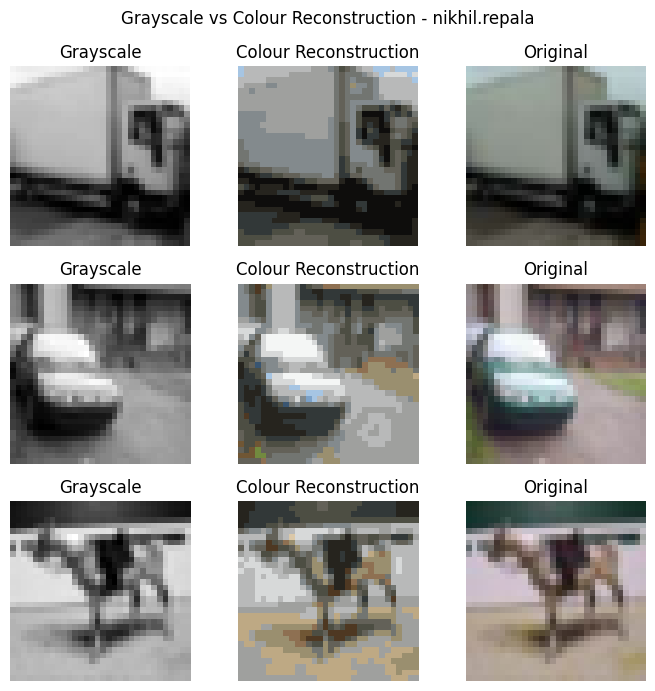

In [10]:
gray_batch,labels_batch,originals=next(iter(train_loader))
print("CHECK")
print("=====")
plt.figure(figsize=(7,7))
plt.suptitle("Grayscale vs Colour Reconstruction - nikhil.repala")

for i in range(3):
  gray=gray_batch[i].squeeze().numpy()
  labels=labels_batch[i].numpy()
  recon=reconstruct_rgb_from_labels(labels,centroids)
  orig=originals[i].permute(1,2,0).numpy()

  plt.subplot(3,3,i*3+1)
  plt.imshow(gray,cmap="gray")
  plt.title("Grayscale")
  plt.axis("off")

  plt.subplot(3,3,i*3+2)
  plt.imshow(recon)
  plt.title("Colour Reconstruction")
  plt.axis("off")

  plt.subplot(3,3,i*3+3)
  plt.imshow(orig)
  plt.title("Original")
  plt.axis("off")

plt.tight_layout()
plt.show()

### CNN Encoder - Decoder Model

In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class ColorizationCNN(nn.Module):
  """
  ColorizationCNN class for colorizing grayscale images.
  """
  def __init__(self,NIC=1,NF=16,NC=24,kernel_size=3):
    """
    Initialize the ColorizationCNN class.
    Arguments:
      NIC: number of input channels (default=1 for grayscale)
      NF: number of filters in the first convolutional layer (default=16)
      NC: number of color centroids / output channels (default=24)
      kernel_size: size of the convolutional kernels (default=3)  
    """
    super(ColorizationCNN,self).__init__()

    padding=kernel_size//2

    self.encoder=nn.Sequential(
        nn.Conv2d(NIC,NF,kernel_size,padding=padding),
        nn.BatchNorm2d(NF),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(NF,NF*2,kernel_size,padding=padding),
        nn.BatchNorm2d(NF*2),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(NF*2,NF*4,kernel_size,padding=padding),
        nn.BatchNorm2d(NF*4),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )

    self.decoder=nn.Sequential(
        nn.ConvTranspose2d(NF*4,NF*2,kernel_size=2,stride=2),
        nn.BatchNorm2d(NF*2),
        nn.ReLU(),

        nn.ConvTranspose2d(NF*2,NF,kernel_size=2,stride=2),
        nn.BatchNorm2d(NF),
        nn.ReLU(),

        nn.ConvTranspose2d(NF,NC,kernel_size=2,stride=2),
        nn.BatchNorm2d(NC),
        nn.ReLU(),
    )

    self.classifier=nn.Conv2d(NC,NC,kernel_size=1)

  def forward(self,x):
    """
    Forward pass of the ColorizationCNN.
    Arguments:  
      x: input tensor of shape (B x 1 x H x W)
    Output:
      classified: output tensor of shape (B x NC x H x W) with class scores for each pixel
    """
    encoded=self.encoder(x)
    decoded=self.decoder(encoded)
    classified=self.classifier(decoded)
    return classified

In [11]:
model=ColorizationCNN(NIC=1,NF=16,NC=24,kernel_size=3)
x=torch.randn(2,1,32,32)
y=model(x)
print("CHECK")
print("=====")
print("Input :",x.shape)
print("Output :",y.shape)

CHECK
=====
Input : torch.Size([2, 1, 32, 32])
Output : torch.Size([2, 24, 32, 32])


### Training and Evaluation

##### For One Epoch

In [ ]:
import torch.optim as optim
from tqdm import tqdm

criterion=nn.CrossEntropyLoss()
optimizer=optim.Adam(model.parameters(),lr=0.001)

def train_one_epoch(model,train_loader,optimizer,criterion,device):
  """
  Train the model for one epoch.
  Arguments:
    model: ColorizationCNN model
    train_loader: DataLoader for training data
    optimizer: optimizer for training
    criterion: loss function
    device: device to run the training on (cpu or cuda)
  """
  model.train()
  train_loss=0.0

  for gray_batch,labels_batch,_ in tqdm(train_loader,desc="Training",leave=False):
    gray_batch=gray_batch.to(device)
    labels_batch=labels_batch.to(device)

    optimizer.zero_grad()
    outputs=model(gray_batch)
    loss=criterion(outputs,labels_batch)
    loss.backward()
    optimizer.step()

    train_loss+=loss.item()

  return train_loss/len(train_loader)


def validate(model,val_loader,criterion,device):
  """
  Validate the model.
  Arguments:
    model: ColorizationCNN model
    val_loader: DataLoader for validation data
    criterion: loss function
    device: device to run the validation on (cpu or cuda)
  Output:
    average validation loss over the validation dataset
  """
  model.eval()
  val_loss=0.0

  with torch.no_grad():
    for gray_batch,labels_batch,_ in tqdm(val_loader,desc="Validation",leave=False):
      gray_batch=gray_batch.to(device)
      labels_batch=labels_batch.to(device)

      outputs=model(gray_batch)
      loss=criterion(outputs,labels_batch)

      val_loss+=loss.item()

  return val_loss/len(val_loader)

In [ ]:
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

train_loss=train_one_epoch(model,train_loader,optimizer,criterion,device)
val_loss=validate(model,val_loader,criterion,device)

print("CHECK")
print("=====")
print("Train Loss: ",train_loss)
print("Validation Loss: ",val_loss)

CHECK
=====
Train Loss:  3.223242251033133
Validation Loss:  3.220581193513508


##### Full Training

In [13]:
# !pip install wandb -qU
import wandb
wandb.login()

/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)


<IPython.core.display.Javascript object>

wandb: Logging into wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: You can find your API key in your browser here: https://wandb.ai/authorize
wandb: Paste an API key from your profile and hit enter:

 ··········


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: nikhilrepala8074 (nikhil_r_8074-iiit-hyderabad) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

In [16]:


wandb.init(
    project="SMAI-Image-Colorization",
    config={
        "epochs":25,
        "batch_size":64,
        "learning_rate":0.001,
        "optimizer":"Adam",
        "NF":16,
        "kernel_size":3
    },
)

config=wandb.config

In [17]:
train_eval_model=ColorizationCNN(NIC=1,NF=config.NF,NC=24,kernel_size=config.kernel_size)
criterion=nn.CrossEntropyLoss()

if config.optimizer=="Adam":
  optimizer=optim.Adam(train_eval_model.parameters(),lr=config.learning_rate)
elif config.optimizer=="SGD":
  optimizer=optim.SGD(train_eval_model.parameters(),lr=config.learning_rate,
                      momentum=0.9)
train_eval_device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
train_eval_model.to(train_eval_device)

ColorizationCNN(
  (encoder): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (decoder): Sequential(
    (0): ConvTranspose2d(64, 32, kernel_size=(2, 2), stride=(2, 2))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track

In [ ]:
import os

best_val_loss=float("inf")
num_epochs=config.epochs
save_path="best_colorization_model.pth"

train_losses=[]
val_losses=[]

for epoch in range(num_epochs):
  train_eval_model.train()
  running_loss=0.0
  for gray_batch,labels_batch,_ in tqdm(train_loader,desc="Training",leave=False):
    gray_batch=gray_batch.to(train_eval_device)
    labels_batch=labels_batch.to(train_eval_device)

    optimizer.zero_grad()
    outputs=train_eval_model(gray_batch)
    loss=criterion(outputs,labels_batch)
    loss.backward()
    optimizer.step()

    running_loss+=loss.item()

  train_loss=running_loss/len(train_loader)

  train_eval_model.eval()
  val_loss=0.0
  with torch.no_grad():
    for gray_batch,labels_batch,_ in tqdm(val_loader,desc="Validation",leave=False):
      gray_batch=gray_batch.to(train_eval_device)
      labels_batch=labels_batch.to(train_eval_device)

      outputs=train_eval_model(gray_batch)
      loss=criterion(outputs,labels_batch)

      val_loss+=loss.item()

  val_loss=val_loss/len(val_loader)

  train_losses.append(train_loss)
  val_losses.append(val_loss)

  wandb.log({
      "Epoch":epoch+1,
      "Train Loss":train_loss,
      "Validation Loss":val_loss
  })

  print(f"Epoch {epoch+1}/{num_epochs} - Train Loss: {train_loss:.4f} - Validation Loss: {val_loss:.4f}")

  if val_loss<best_val_loss:
    best_val_loss=val_loss
    torch.save(train_eval_model.state_dict(),save_path)
    print("Model saved")

print("Training completed! Best validation loss: ",best_val_loss)


Epoch 1/25 - Train Loss: 2.1966 - Validation Loss: 1.9287
Model saved


Epoch 2/25 - Train Loss: 1.9267 - Validation Loss: 1.8904
Model saved


Epoch 3/25 - Train Loss: 1.8755 - Validation Loss: 1.8343
Model saved


Epoch 4/25 - Train Loss: 1.8561 - Validation Loss: 1.8107
Model saved


Epoch 5/25 - Train Loss: 1.8328 - Validation Loss: 1.7860
Model saved


...

Epoch 21/25 - Train Loss: 1.7582 - Validation Loss: 1.7362


Epoch 22/25 - Train Loss: 1.7574 - Validation Loss: 1.7337


Epoch 23/25 - Train Loss: 1.7558 - Validation Loss: 1.7189
Model saved


Epoch 24/25 - Train Loss: 1.7531 - Validation Loss: 1.7507


Epoch 25/25 - Train Loss: 1.7508 - Validation Loss: 1.7364
Training completed! Best validation loss:  1.7188736139973508


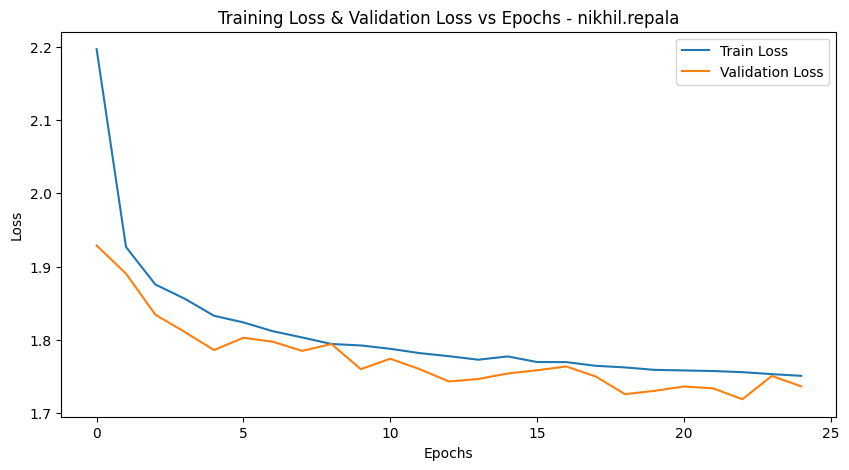

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(train_losses,label="Train Loss")
plt.plot(val_losses,label="Validation Loss")
plt.title("Training Loss & Validation Loss vs Epochs - nikhil.repala")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

##### 10 Examples Colorization

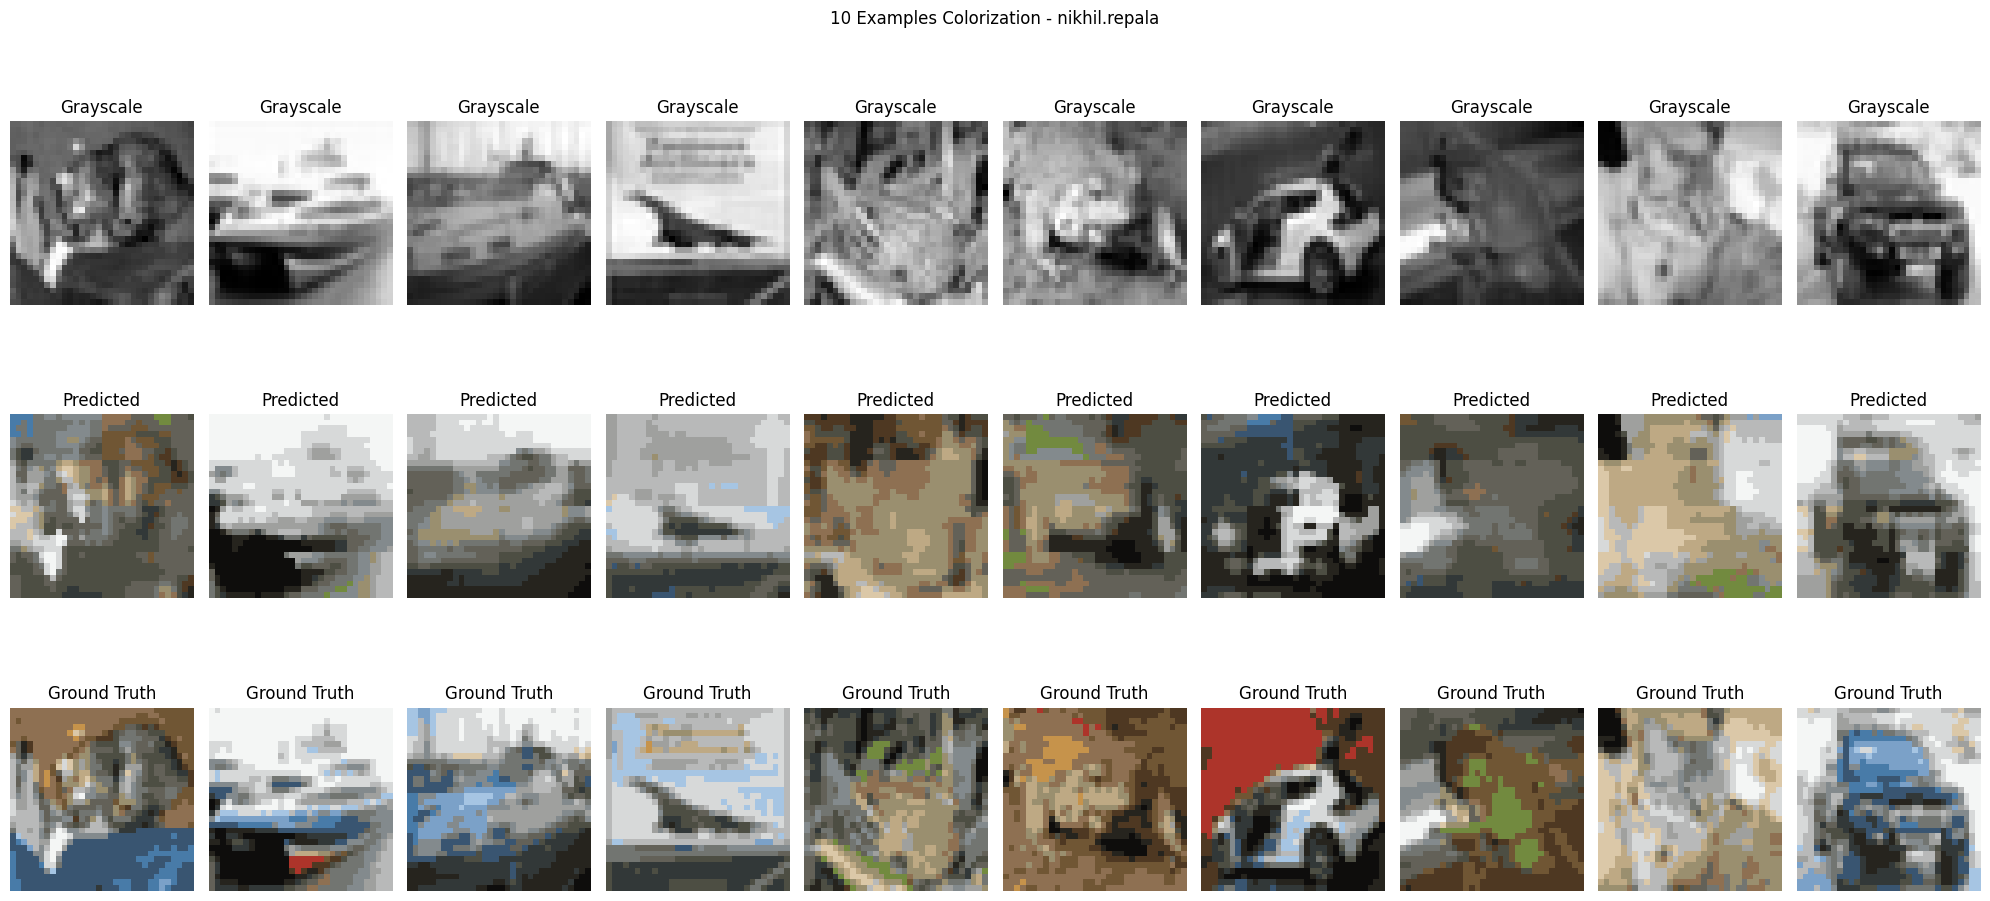

In [ ]:
train_eval_model.load_state_dict(torch.load(save_path,map_location=train_eval_device))
train_eval_model.eval()


gray_batch,labels_batch,originals=next(iter(test_loader))
gray_batch=gray_batch[:10].to(train_eval_device)
labels_batch=labels_batch[:10]

with torch.no_grad():
  outputs=train_eval_model(gray_batch).argmax(dim=1).cpu().numpy()

plt.figure(figsize=(20,10))
plt.suptitle("10 Examples Colorization - nikhil.repala")
for i in range(10):
  gray=gray_batch[i].cpu().squeeze().numpy()
  pred_label=outputs[i]
  gt_label=labels_batch[i].numpy()

  recon_pred=reconstruct_rgb_from_labels(pred_label,centroids)
  recon_gt=reconstruct_rgb_from_labels(gt_label,centroids)

  plt.subplot(3,10,i+1)
  plt.imshow(gray,cmap="gray")
  plt.title("Grayscale")
  plt.axis("off")

  plt.subplot(3,10,i+1+10)
  plt.imshow(recon_pred)
  plt.title("Predicted")
  plt.axis("off")

  plt.subplot(3,10,i+1+20)
  plt.imshow(recon_gt)
  plt.title("Ground Truth")
  plt.axis("off")

plt.tight_layout()
plt.show()

In [18]:
wandb.finish()

## Wandb Link for manual single run : [LINK](https://wandb.ai/nikhil_r_8074-iiit-hyderabad/SMAI-Image-Colorization)

### Analytic Questions

**Model** - Encoder Decoder using conv2d and ConvTranspose2d layers.  
Architecture follows:
- 3 encoder blocks (kernel size = 3, stride = 1, padding = 1) with MaxPool2d(2)
- 3 decoder transpose-conv blocks (kernel size = 2,stride = 2)
- Final 1×1 conv classifier

**Symbols :**

| Symbol | Meaning |
|:-------|:--------|
| **NIC** | Number of input channels|
| **NF** | Base Number of filters in first conv layer|
| **NC** | Number of color classes |
| **K** | Kernel size of encoder convs|
| **Kt** | Kernel size of transpose convs|
| **S** | Input size|


**Assumptions :**
- Each MaxPool2d(2) halves the spatial size
- Each convTranspose2d doubles the spatial size
- Bias and BatchNorm are ignored
- Padding preserves the spatial size

### 1. Number of Weights

Weigths = Σ (Cin × Cout × Kernel²) over all the conv and conv-transpose layers.

**Encoder Weights**

| Layer | Weights |
|:------|:--------|
|Conv1 : NIC → NF  |   NIC * NF * K²|
|Conv2 : NF → 2NF  |   2 * NF² * K² |
|Conv3 : 2NF → 4NF  |   8 * NF² * K² |

**Decoder Weights**

| Layer | Weights |
|:------|:--------|
|Conv-Transpose1 : 4NF → 2NF  |    8 * NF² * Kt²|
|Conv-Transpose2 : 2NF → NF  |   2 * NF² * Kt² |
|Conv-Transpose3 : NF → NC  |    NF * NC *Kt² |

**Classifier**
| Layer | Weights |
|:------|:--------|
| 1x1 conv : NC → NC |  NC² |

**Total (ignoring Bias & BatchNorm) :**

W = NIC·NF·K² + 10·NF²·K² + 10·NF²·Kt² + NF·NC·Kt² + NC²

as K = 3 , Kt = 2 , NIC = 1 , NF = 16, NC = 24

\[
W = 9·1·16 + 130·16² + 4·16·24 + 24²
\]

so W = 35536

### 2. Number of Outputs

Total number of activation elements (neurons) across all layers for one input.

| Layer | Channels | Spatial Size | Activations |
|:------|:----------|:--------------|:-------------|
| Enc1 | NF | (S/2)² | NF·S²/4 |
| Enc2 | 2NF | (S/4)² | 2NF·S²/16 |
| Enc3 | 4NF | (S/8)² | 4NF·S²/64 |
| Dec1 | 2NF | (S/4)² | 2NF·S²/16 |
| Dec2 | NF | (S/2)² | NF·S²/4 |
| Dec3 | NC | S² | NC·S² |
| Classifier | NC | S² | NC·S² |


**Total Ouputs**

A = S²·((13/16)·NF + 2·NC)

as S = 32 , NF = 16 , NC = 24

\[
A = 32²·((13/16)·16 + 2·24)
\]

so A = 62464

### 3. Number of Connections

Each weight connects to one receptive field region of size K×K in each output location.

For convolutional layers,
Connections per layer = Cout · H_out · W_out · Cin · K².
(where H_out and W_out are the output spatial dimensions).

| Layer | Channels | Spatial Size | Number of Connections |
|:------|:----------|:--------------------|:-----------------------|
| Conv1 | NIC → NF | S² | NF·S²·NIC·K² |
| Conv2 | NF → 2NF | (S/2)² | (1/2)·NF²·S²·K² |
| Conv3 | 2NF → 4NF | (S/4)² | (1/2)·NF²·S²·K² |
| T1 | 4NF → 2NF | (S/8)² | (1/8)·NF²·S²·Kt² |
| T2 | 2NF → NF | (S/4)² | (1/8)·NF²·S²·Kt²  |
| T3 | NF → NC | (S/2)² |(1/4)·NF·NC·S²·Kt² |
| Classifier | NC → NC | S² | NC²·S² |

**Total Connection**

C = S²·(K²·(NIC·NF+NF²) + (1/4)·Kt²·(NF²+NC·NF) + NC²)

as NIC = 1 , NF = 16 , NC = 24, K = 3 , Kt = 2, S = 32

\[
C = 32²·(3²·(1·16+16²) + (1/4)·2²·(16²+24·16) + 24²)
\]

so C = 3751936


## Input Size Doubled (S→2S)

| Quantity | Change | Reason |
|:----------|:--------|:--------|
| **Weights** | Unchanged | Filter count independent of spatial size |
| **Outputs** | ×4 |  Number of Outputs ∝ S² |
| **Connections** | ×4 | Number of Connections ∝ S² |


So, For S' = 2S

W' = W = 35536

A' = 4A = 4·62464 = 249856

C' = 4C = 4.3751936 = 15007744


## Hyperparameter Training

In [ ]:
sweep_config={
    'method': 'random',
    'name' : 'colorization_sweep',
    'metric':{
        'name':'Validation Loss',
        'goal':'minimize'
    },
    'parameters':{
        'learning_rate': {'values': [1e-4, 3e-4, 1e-3, 3e-3]},
        'batch_size': {'values': [32, 64, 128]},
        'NF': {'values': [8, 16, 32]},
        'kernel_size': {'values': [3, 5]},
        'optimizer': {'values': ['Adam', 'SGD']}
    }
}

sweep_id=wandb.sweep(sweep_config,project="SMAI-Image-Colorization-Sweep")

Create sweep with ID: 3dkvfev1
Sweep URL: https://wandb.ai/nikhil_r_8074-iiit-hyderabad/SMAI-Image-Colorization-Sweep/sweeps/3dkvfev1


In [ ]:
def train_sweep():
  """
  Train the model on the sweep configuration.
  """
  wandb.init(project="SMAI-Image-Colorization-Sweep")
  config=wandb.config

  sweep_model=ColorizationCNN(NIC=1,NF=config.NF,NC=24,kernel_size=config.kernel_size)
  sweep_device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
  sweep_model.to(sweep_device)

  for layer in sweep_model.encoder:
    if isinstance(layer,nn.Conv2d):
      layer.padding=(config.kernel_size//2,config.kernel_size//2)

  sweep_train_loader=DataLoader(train_dataset,batch_size=config.batch_size,shuffle=True,num_workers=2)
  sweep_val_loader=DataLoader(val_dataset,batch_size=config.batch_size,shuffle=False,num_workers=2)

  if config.optimizer=="Adam":
    sweep_optimizer=optim.Adam(sweep_model.parameters(),lr=config.learning_rate)
  elif config.optimizer=="SGD":
    sweep_optimizer=optim.SGD(sweep_model.parameters(),lr=config.learning_rate,
                              momentum=0.9)
  criterion=nn.CrossEntropyLoss()
  best_val_loss=float("inf")


  for epoch in range(15):
    sweep_model.train()
    running_loss=0.0
    for gray_batch,labels_batch,_ in tqdm(sweep_train_loader,desc="Training",leave=False):
      gray_batch=gray_batch.to(sweep_device)
      labels_batch=labels_batch.to(sweep_device)

      sweep_optimizer.zero_grad()
      outputs=sweep_model(gray_batch)
      loss=criterion(outputs,labels_batch)
      loss.backward()
      sweep_optimizer.step()

      running_loss+=loss.item()

    train_loss=running_loss/len(sweep_train_loader)

    sweep_model.eval()
    val_loss=0.0
    with torch.no_grad():
      for gray_batch,labels_batch,_ in tqdm(sweep_val_loader,desc="Validation",leave=False):
        gray_batch=gray_batch.to(sweep_device)
        labels_batch=labels_batch.to(sweep_device)

        outputs=sweep_model(gray_batch)
        loss=criterion(outputs,labels_batch)

        val_loss+=loss.item()

    val_loss=val_loss/len(sweep_val_loader)
    wandb.log({
        "Epoch":epoch+1,
        "Train Loss":train_loss,
        "Validation Loss":val_loss
    })

    if val_loss<best_val_loss:
      best_val_loss=val_loss
      torch.save(sweep_model.state_dict(),f"best_model_{wandb.run.id}.pth")

  best_checkpoint=wandb.Artifact("best_model",type="model")
  best_checkpoint.add_file(f"best_model_{wandb.run.id}.pth")
  wandb.log_artifact(best_checkpoint)

  sweep_model.load_state_dict(torch.load(f"best_model_{wandb.run.id}.pth",map_location=sweep_device))
  sweep_model.eval()
  gray_batch,labels_batch,originals=next(iter(test_loader))
  gray_batch=gray_batch[:10].to(sweep_device)
  labels_batch=labels_batch[:10]
  originals=originals[:10]

  with torch.no_grad():
    outputs=sweep_model(gray_batch).argmax(dim=1).cpu().numpy()

  examples=[]
  for i in range(10):
    gray=gray_batch[i].cpu().squeeze().numpy()
    pred_label=outputs[i]
    gt_label=labels_batch[i].numpy()
    recon_pred=reconstruct_rgb_from_labels(pred_label,centroids)
    recon_gt=reconstruct_rgb_from_labels(gt_label,centroids)

    comparision=np.hstack((recon_pred,recon_gt))
    examples.append(
        wandb.Image(
            comparision,
            caption=f"Example: {i+1} : Left = Predicted, Right = Ground Truth"
        )
    )

  wandb.log({
      "Example Colorization":examples,
      "Best Validation Loss":best_val_loss
  })


  wandb.finish()


## Wandb Sweep Link : [Link](https://wandb.ai/nikhil_r_8074-iiit-hyderabad/SMAI-Image-Colorization-Sweep)

In [ ]:
wandb.agent(sweep_id,function=train_sweep,count=3)

wandb: Agent Starting Run: pthvx4dr with config:
wandb: 	NF: 16
wandb: 	batch_size: 32
wandb: 	kernel_size: 3
wandb: 	learning_rate: 0.0003
wandb: 	optimizer: Adam


Best Validation Loss,▁
Epoch,▁▁▂▃▃▃▄▅▅▅▆▇▇▇█
Train Loss,█▄▃▂▂▂▂▂▁▁▁▁▁▁▁
Validation Loss,█▅▄▄▃▂▃▂▂▂▁▁▁▁▁
Best Validation Loss,1.76291
Epoch,15
Train Loss,1.82329
Validation Loss,1.76291


wandb: Agent Starting Run: jzxt9liq with config:
wandb: 	NF: 16
wandb: 	batch_size: 128
wandb: 	kernel_size: 5
wandb: 	learning_rate: 0.0001
wandb: 	optimizer: Adam


Best Validation Loss,▁
Epoch,▁▁▂▃▃▃▄▅▅▅▆▇▇▇█
Train Loss,█▆▄▃▃▂▂▂▂▂▁▁▁▁▁
Validation Loss,█▆▄▄▃▃▂▂▂▂▁▁▁▁▁
Best Validation Loss,1.74061
Epoch,15
Train Loss,1.7631
Validation Loss,1.74061


wandb: Agent Starting Run: p7rzq9r5 with config:
wandb: 	NF: 16
wandb: 	batch_size: 64
wandb: 	kernel_size: 5
wandb: 	learning_rate: 0.0003
wandb: 	optimizer: SGD


Best Validation Loss,▁
Epoch,▁▁▂▃▃▃▄▅▅▅▆▇▇▇█
Train Loss,█▇▆▆▅▄▄▃▃▂▂▂▁▁▁
Validation Loss,█▇▆▆▅▄▄▃▃▂▂▂▁▁▁
Best Validation Loss,2.27112
Epoch,15
Train Loss,2.29025
Validation Loss,2.27112


wandb: Agent Starting Run: 8zwrqq5s with config:
wandb: 	NF: 16
wandb: 	batch_size: 64
wandb: 	kernel_size: 3
wandb: 	learning_rate: 0.003
wandb: 	optimizer: Adam


Training:  81%|████████  | 571/704 [00:37<00:07, 17.63it/s]

In [21]:
sweep_id= "3dkvfev1"
wandb.agent(sweep_id,function=train_sweep,count=17,project="SMAI-Image-Colorization-Sweep")


wandb: Agent Starting Run: jslza363 with config:
wandb: 	NF: 32
wandb: 	batch_size: 32
wandb: 	kernel_size: 5
wandb: 	learning_rate: 0.001
wandb: 	optimizer: Adam


Best Validation Loss,▁
Epoch,▁▁▂▃▃▃▄▅▅▅▆▇▇▇█
Train Loss,█▄▄▃▃▃▂▂▂▂▁▁▁▁▁
Validation Loss,█▆▆▅▄▃▃▂▅▂▄▂▁▁▁
Best Validation Loss,1.41989
Epoch,15
Train Loss,1.43516
Validation Loss,1.41989


wandb: Agent Starting Run: 9cmzhs72 with config:
wandb: 	NF: 32
wandb: 	batch_size: 64
wandb: 	kernel_size: 3
wandb: 	learning_rate: 0.001
wandb: 	optimizer: Adam


Best Validation Loss,▁
Epoch,▁▁▂▃▃▃▄▅▅▅▆▇▇▇█
Train Loss,█▄▃▂▂▂▂▂▁▁▁▁▁▁▁
Validation Loss,█▇▅▄▅▃▃▂▂▃▃▁▁▂▂
Best Validation Loss,1.61822
Epoch,15
Train Loss,1.64934
Validation Loss,1.66489


wandb: Agent Starting Run: m5kkyb08 with config:
wandb: 	NF: 32
wandb: 	batch_size: 128
wandb: 	kernel_size: 3
wandb: 	learning_rate: 0.0003
wandb: 	optimizer: SGD


...

Best Validation Loss,▁
Epoch,▁▁▂▃▃▃▄▅▅▅▆▇▇▇█
Train Loss,█▇▇▆▆▅▅▄▄▃▃▂▂▁▁
Validation Loss,█▇▇▆▆▅▅▄▄▃▃▂▂▁▁
Best Validation Loss,2.96269
Epoch,15
Train Loss,2.96878
Validation Loss,2.96269


wandb: Agent Starting Run: zlyl0qfa with config:
wandb: 	NF: 32
wandb: 	batch_size: 64
wandb: 	kernel_size: 3
wandb: 	learning_rate: 0.0001
wandb: 	optimizer: Adam


Best Validation Loss,▁
Epoch,▁▁▂▃▃▃▄▅▅▅▆▇▇▇█
Train Loss,█▅▃▃▂▂▂▂▁▁▁▁▁▁▁
Validation Loss,█▅▄▃▃▂▂▂▂▁▁▁▁▁▁
Best Validation Loss,1.72652
Epoch,15
Train Loss,1.75613
Validation Loss,1.72652


wandb: Agent Starting Run: tuplfnov with config:
wandb: 	NF: 32
wandb: 	batch_size: 64
wandb: 	kernel_size: 3
wandb: 	learning_rate: 0.0003
wandb: 	optimizer: SGD


Best Validation Loss,▁
Epoch,▁▁▂▃▃▃▄▅▅▅▆▇▇▇█
Train Loss,█▇▆▆▅▄▄▃▃▂▂▂▂▁▁
Validation Loss,█▇▇▆▅▄▄▃▃▃▂▂▂▁▁
Best Validation Loss,2.27195
Epoch,15
Train Loss,2.2932
Validation Loss,2.27195


### BEST RUN :
  
  vivid-sweep-4 : [SEE RUN](https://wandb.ai/nikhil_r_8074-iiit-hyderabad/SMAI-Image-Colorization-Sweep/runs/jslza363)

  Hyper parameters :  

  | Parameter | Value |
  |:----------|:--------|
  | **NIC** | 1 |
  | **NF** | 32 |
  | **NC** | 24 |
  | **kernel_size** | 5 |
  | **batch_size** | 32 |
  | **learning_rate** | 0.001 |
  | **optimizer** | Adam |

  Best Validation Loss : 1.41988721167206 at Epoch 15